# Notebook 2 — Threshold Analysis

**Purpose:** Understand how threshold choices affect performance per experiment.

**Input:** Same `stdout.log` files as Notebook 1.

**Outputs:**
- F-measure vs detection threshold `k` (line plot, one line per experiment)
- F-measure vs adaptive post-proc threshold A (0.2–0.5), per experiment
- F-measure vs length post-proc threshold B (0.05–0.20), per experiment
- Heatmap: detection threshold × post-proc threshold → F-measure (one per experiment)
- Best winning threshold analysis across experiments

## 0 — Configuration

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path(".").resolve()))
import parse_logs as pl

# ── Experiment log paths ───────────────────────────────────────────────────
EXPERIMENT_LOGS = {
    "Baseline":            "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/baseline_seed1234/2026-09-17_09-08-46/stdout.log",  # e.g. "../logs/experiments/runs/baseline/2026-.../stdout.log"
    "CIFE":                "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/cife_seed1234/2026-09-17_22-11-22/stdout.log",
    "Slot Uniform":        "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/slot_uniform_seed1234/2026-09-18_12-05-18/stdout.log",
    "Phase 1 (Random)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase1_random_seed1234/2026-09-18_05-15-56/stdout.log",
    "Phase 2 (Energy)":    "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase2_energy_seed1234/2026-09-18_16-56-51/stdout.log",
    "Phase 3 (Activation)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/phase3_seed1234_output.log",
    "AFRI (Direct)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/afri_direct_seed1234/2026-09-19_14-20-53/stdout.log",
    "AFRI (Inverse)": "/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/logs/experiments/runs/afri_inverse_seed1234/2026-09-19_20-45-13/stdout.log",
}


logs_to_parse = {k: v for k, v in EXPERIMENT_LOGS.items() if v is not None}
print(f"Parsing {len(logs_to_parse)} experiment(s)...")

Parsing 8 experiment(s)...


## 1 — Load & Parse Logs

In [2]:
experiments = pl.load_experiments(logs_to_parse)

  ✓ Baseline                        fmeasure=16.615
  ✓ CIFE                            fmeasure=15.296
  ✓ Slot Uniform                    fmeasure=15.392
  ✓ Phase 1 (Random)                fmeasure=15.618
  ✓ Phase 2 (Energy)                fmeasure=15.434
  ✓ Phase 3 (Activation)            fmeasure=15.304
  ✓ AFRI (Direct)                   fmeasure=15.502
  ✓ AFRI (Inverse)                  fmeasure=15.613


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "font.size": 11,
})

COLORS = plt.cm.tab10.colors
exp_labels = list(experiments.keys())

df_nopost  = pl.no_postproc_df(experiments)
df_sweepA  = pl.sweep_A_df(experiments)
df_sweepB  = pl.sweep_B_df(experiments)
df_final   = pl.final_results_df(experiments)

print(f"No-postproc rows : {len(df_nopost)}")
print(f"Sweep A rows     : {len(df_sweepA)}")
print(f"Sweep B rows     : {len(df_sweepB)}")

No-postproc rows : 159
Sweep A rows     : 636
Sweep B rows     : 640


## 2 — F-measure vs Detection Threshold `k`

No post-processing applied — raw model output at each detection threshold.

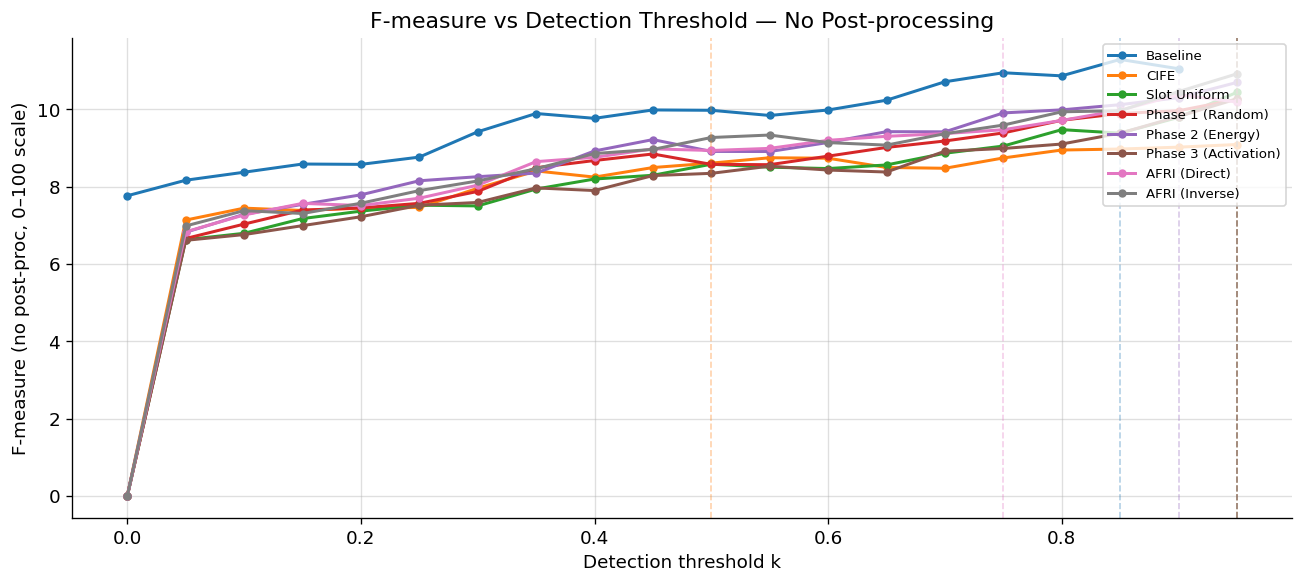

In [4]:
if df_nopost.empty:
    print("No-postproc data not available.")
else:
    fig, ax = plt.subplots(figsize=(11, 5))

    for i_e, label in enumerate(exp_labels):
        sub = df_nopost[df_nopost["experiment"] == label].sort_values("k")
        if sub.empty:
            continue
        ax.plot(sub["k"], sub["fmeasure"], marker="o", markersize=4,
                color=COLORS[i_e % len(COLORS)], label=label, linewidth=1.8)

    # Mark each experiment's winning detection threshold (from best_A/best_B)
    for i_e, (label, data) in enumerate(experiments.items()):
        if data is None:
            continue
        # Winning detection threshold = the k of the globally best entry
        final_fm = data["final"].get("fmeasure")
        for entry in data["best_A"] + data["best_B"]:
            if entry.get("fmeasure") == final_fm:
                ax.axvline(entry["k"], color=COLORS[i_e % len(COLORS)],
                           linestyle="--", alpha=0.35, linewidth=1)
                break

    ax.set_xlabel("Detection threshold k")
    ax.set_ylabel("F-measure (no post-proc, 0–100 scale)")
    ax.set_title("F-measure vs Detection Threshold — No Post-processing")
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.savefig("fig_thresh_sweep_k.pdf", bbox_inches="tight")
    plt.show()

## 3 — F-measure vs Adaptive Post-proc Threshold A (0.2–0.5)

Each curve shows best F across all `k` values for each `thresh_a`.

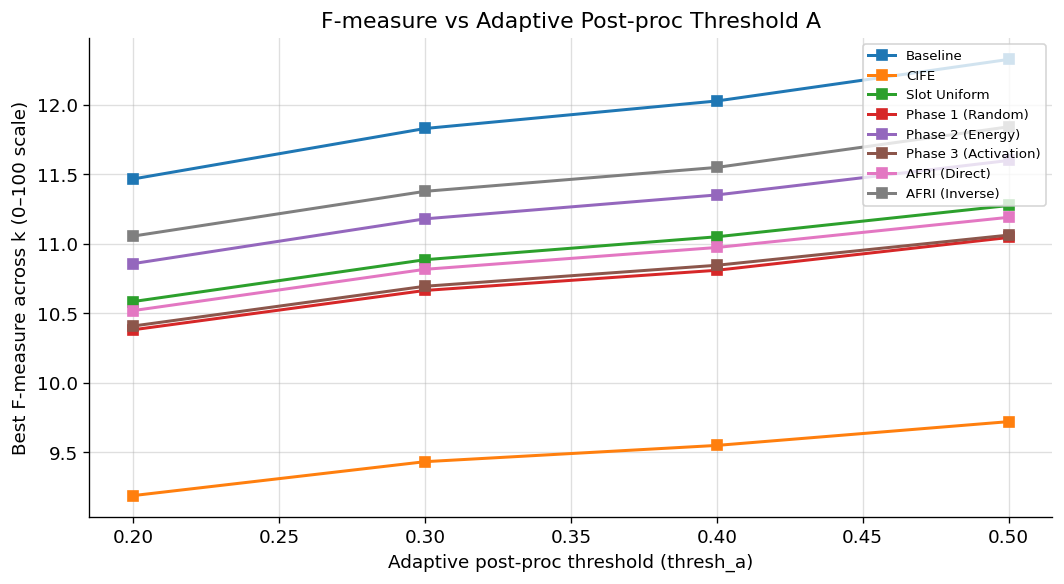

In [5]:
if df_sweepA.empty:
    print("Sweep A data not available.")
else:
    # Best F-measure over all k, for each (experiment, thresh_a)
    df_A_agg = (
        df_sweepA
        .groupby(["experiment", "thresh_a"])["fmeasure"]
        .max()
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    for i_e, label in enumerate(exp_labels):
        sub = df_A_agg[df_A_agg["experiment"] == label].sort_values("thresh_a")
        if sub.empty:
            continue
        ax.plot(sub["thresh_a"], sub["fmeasure"], marker="s", markersize=6,
                color=COLORS[i_e % len(COLORS)], label=label, linewidth=1.8)

    ax.set_xlabel("Adaptive post-proc threshold (thresh_a)")
    ax.set_ylabel("Best F-measure across k (0–100 scale)")
    ax.set_title("F-measure vs Adaptive Post-proc Threshold A")
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.savefig("fig_sweep_A.pdf", bbox_inches="tight")
    plt.show()

## 4 — F-measure vs Length Post-proc Threshold B (0.05–0.20)

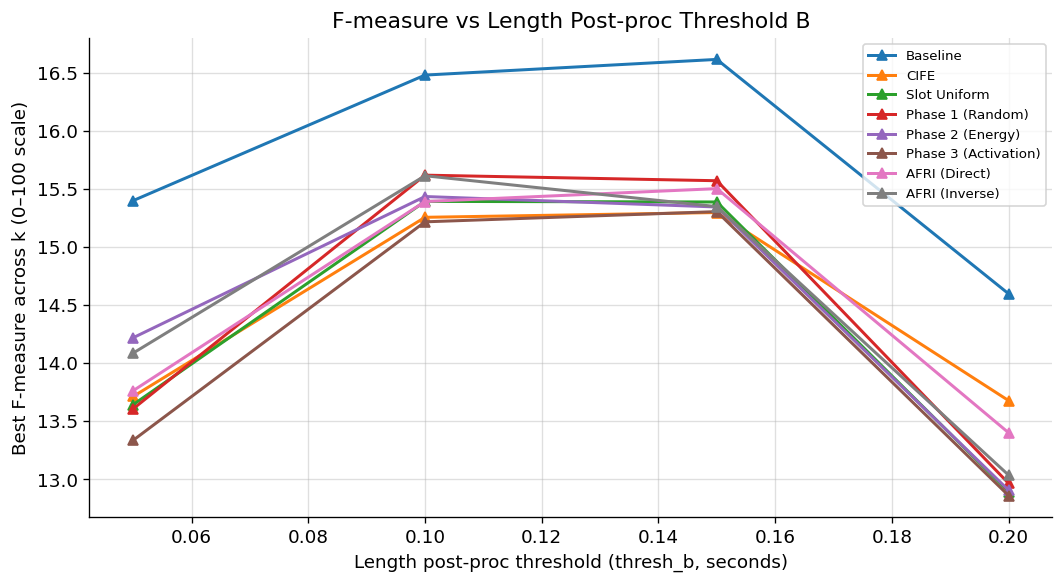

In [6]:
if df_sweepB.empty:
    print("Sweep B data not available.")
else:
    df_B_agg = (
        df_sweepB
        .groupby(["experiment", "thresh_b"])["fmeasure"]
        .max()
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    for i_e, label in enumerate(exp_labels):
        sub = df_B_agg[df_B_agg["experiment"] == label].sort_values("thresh_b")
        if sub.empty:
            continue
        ax.plot(sub["thresh_b"], sub["fmeasure"], marker="^", markersize=6,
                color=COLORS[i_e % len(COLORS)], label=label, linewidth=1.8)

    ax.set_xlabel("Length post-proc threshold (thresh_b, seconds)")
    ax.set_ylabel("Best F-measure across k (0–100 scale)")
    ax.set_title("F-measure vs Length Post-proc Threshold B")
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.savefig("fig_sweep_B.pdf", bbox_inches="tight")
    plt.show()

## 5 — Heatmap: Detection Threshold × Post-proc Threshold → F-measure

One heatmap per experiment × post-proc type.  
Shows the full search space and where the optimum lies.

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


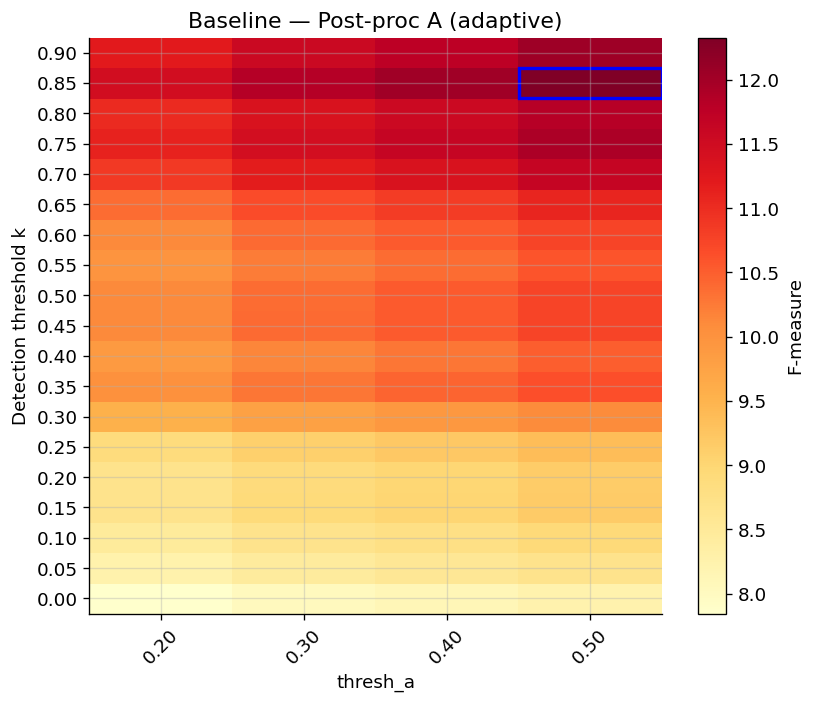

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


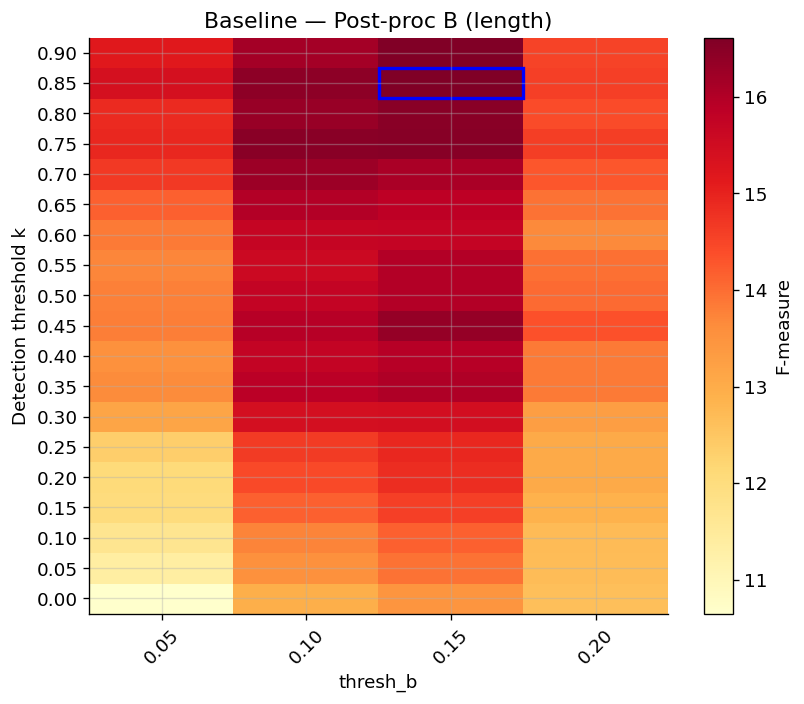

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


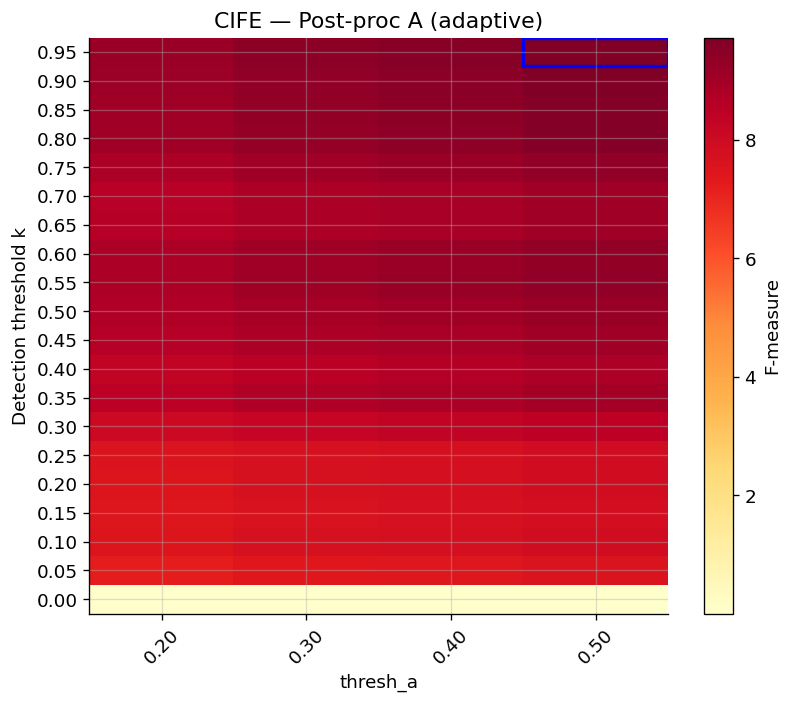

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


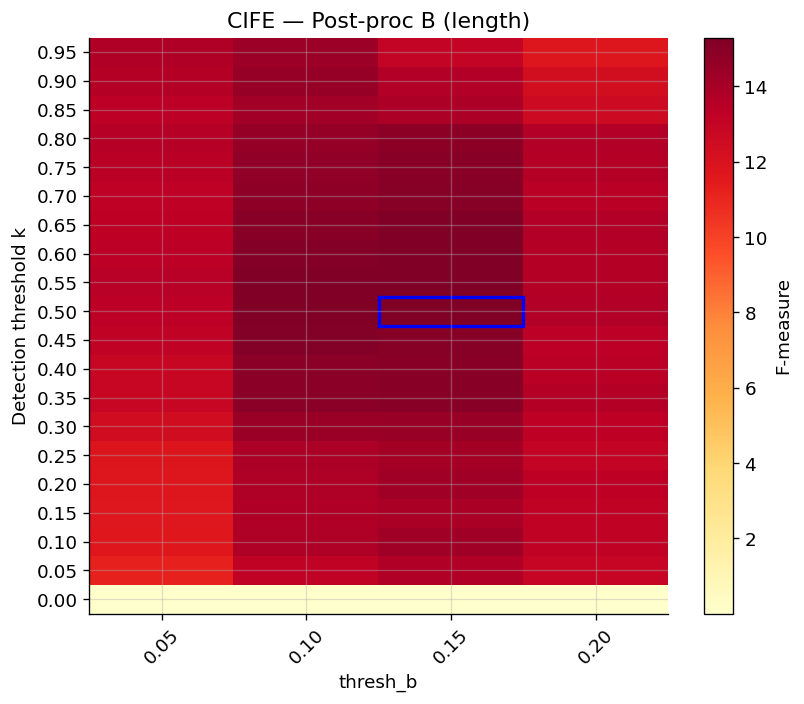

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


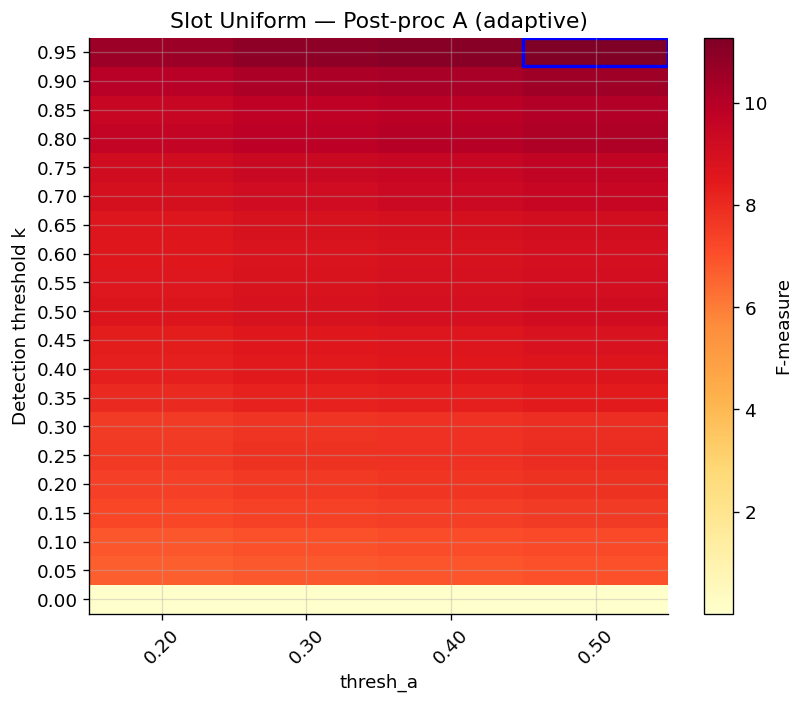

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


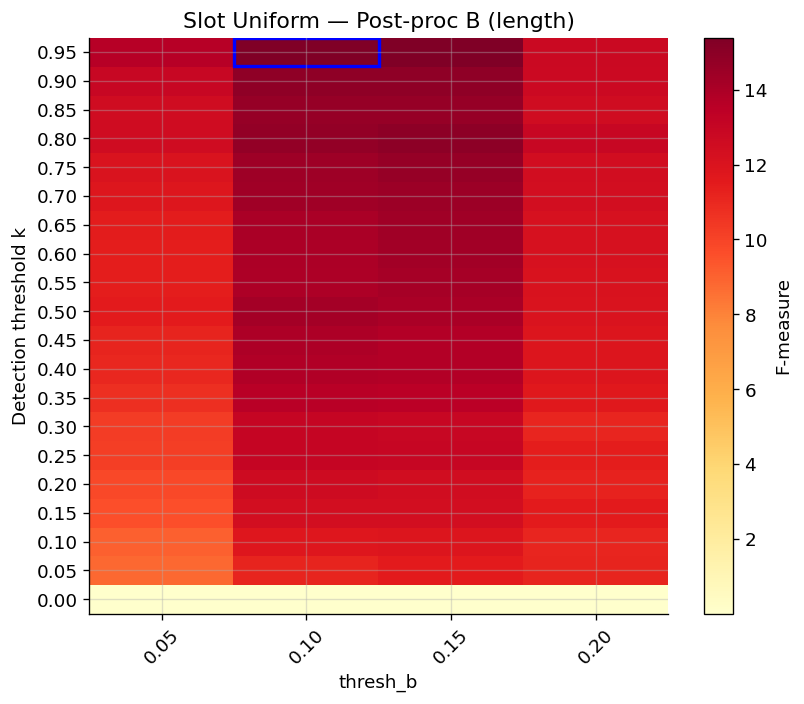

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


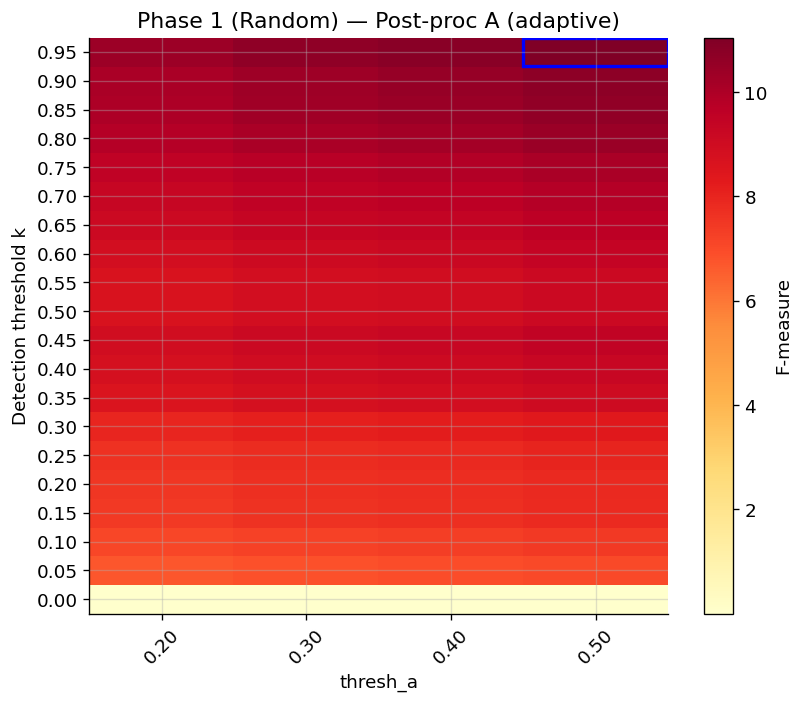

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


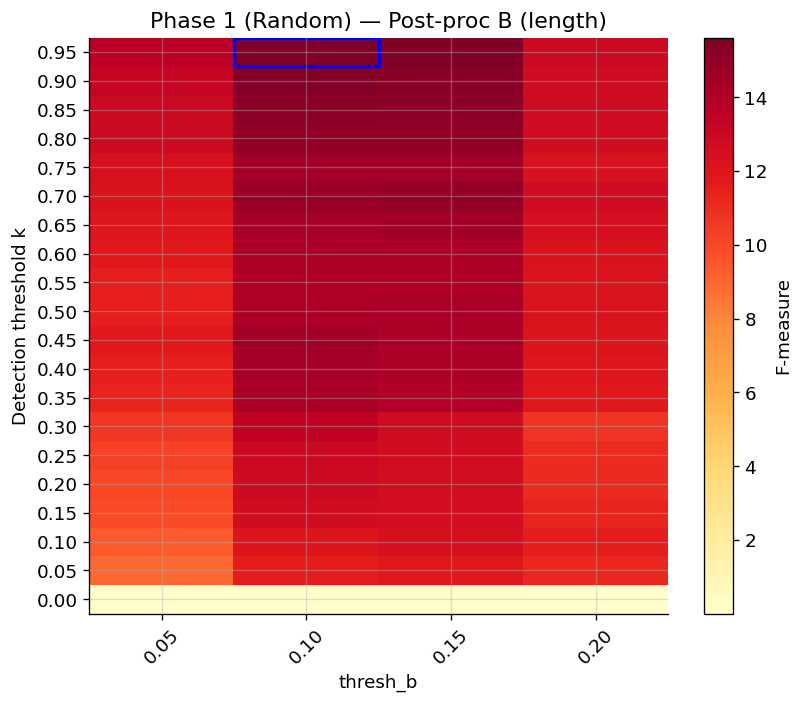

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


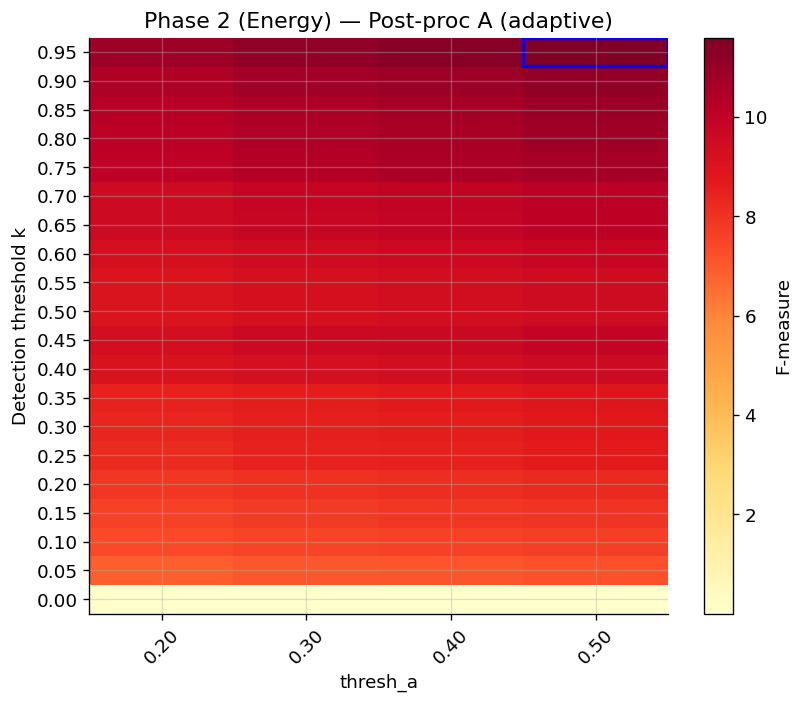

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


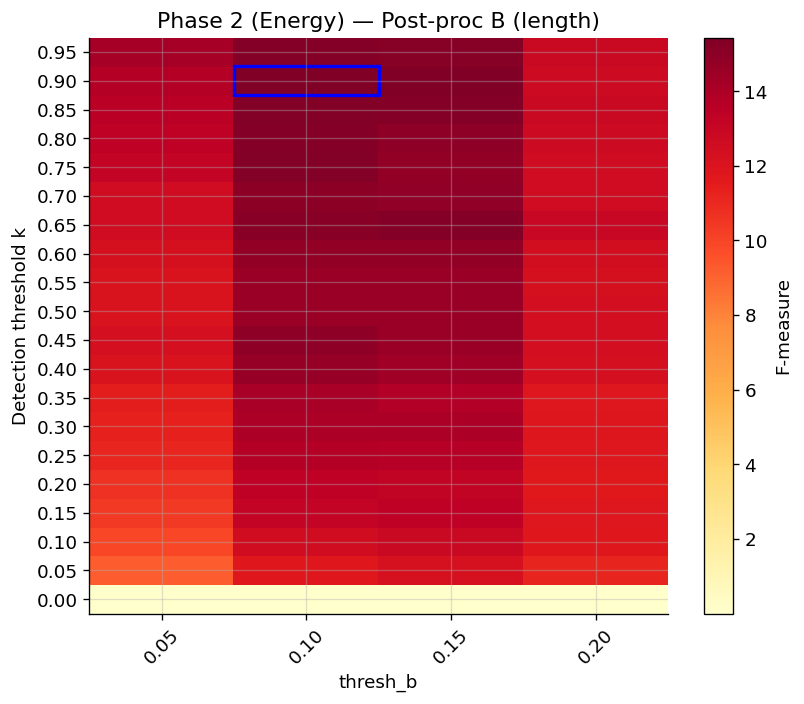

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


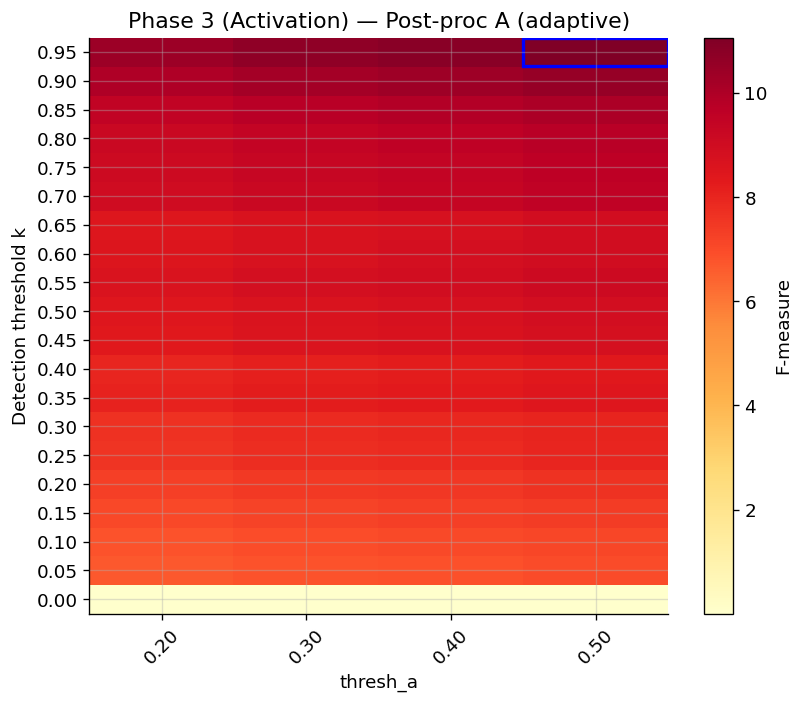

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


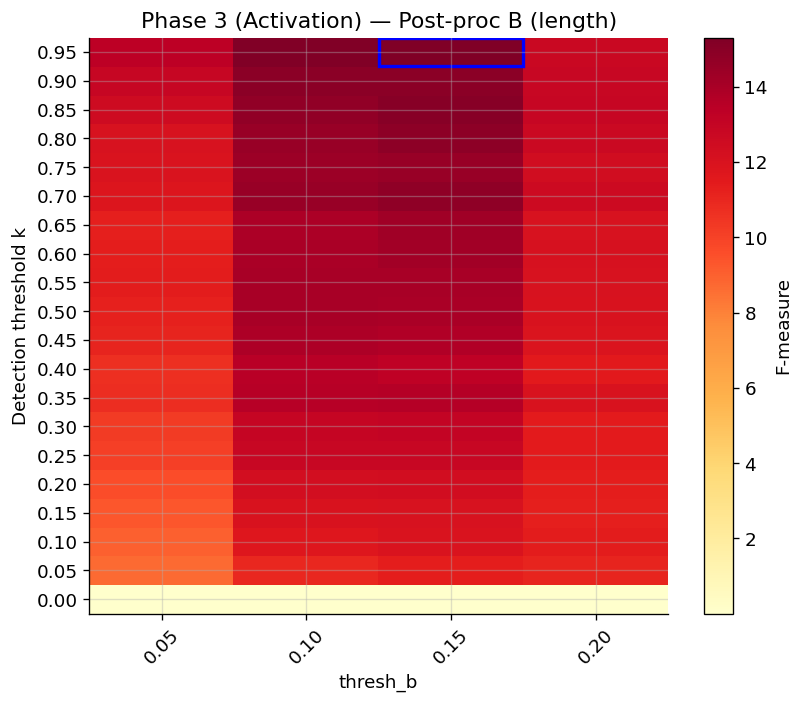

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


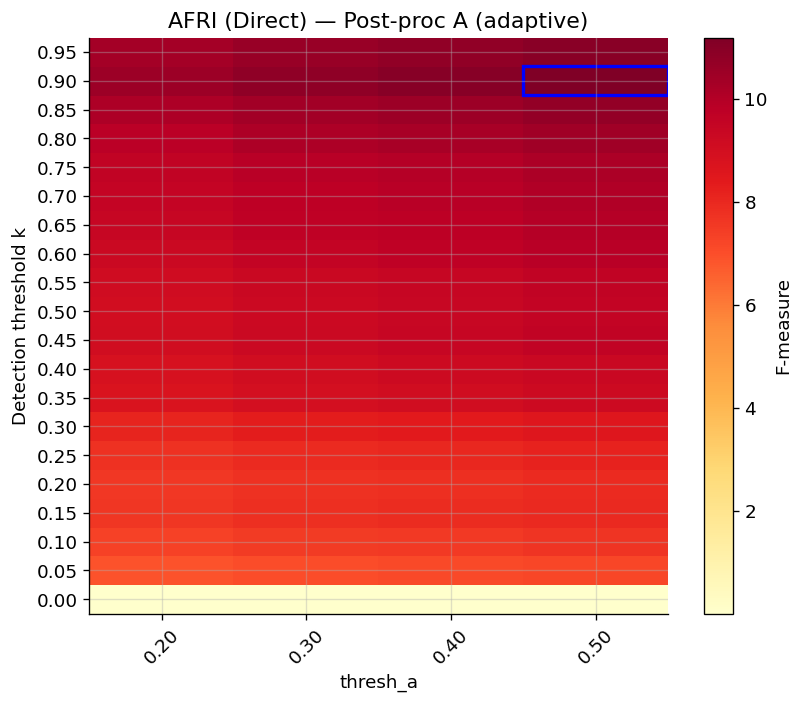

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


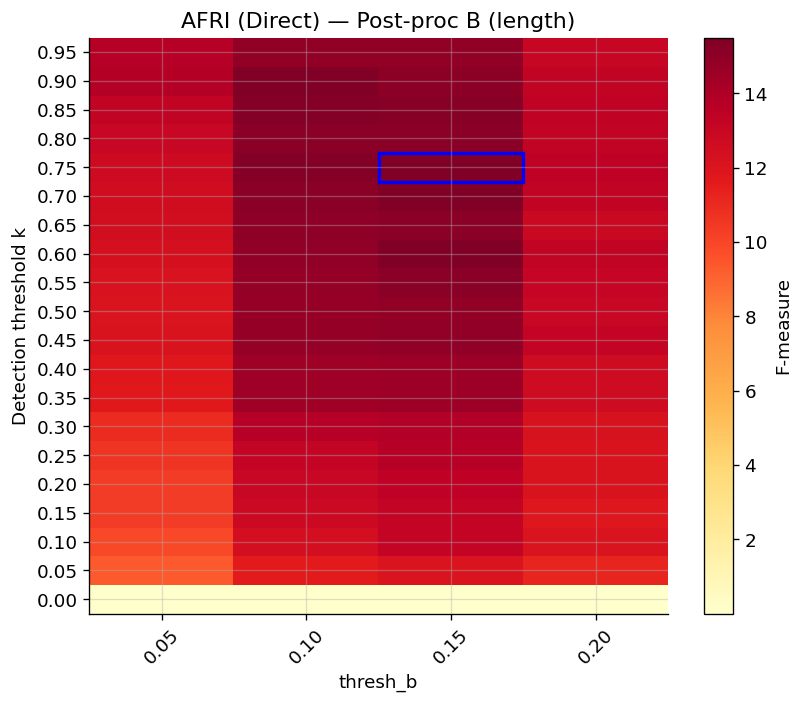

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


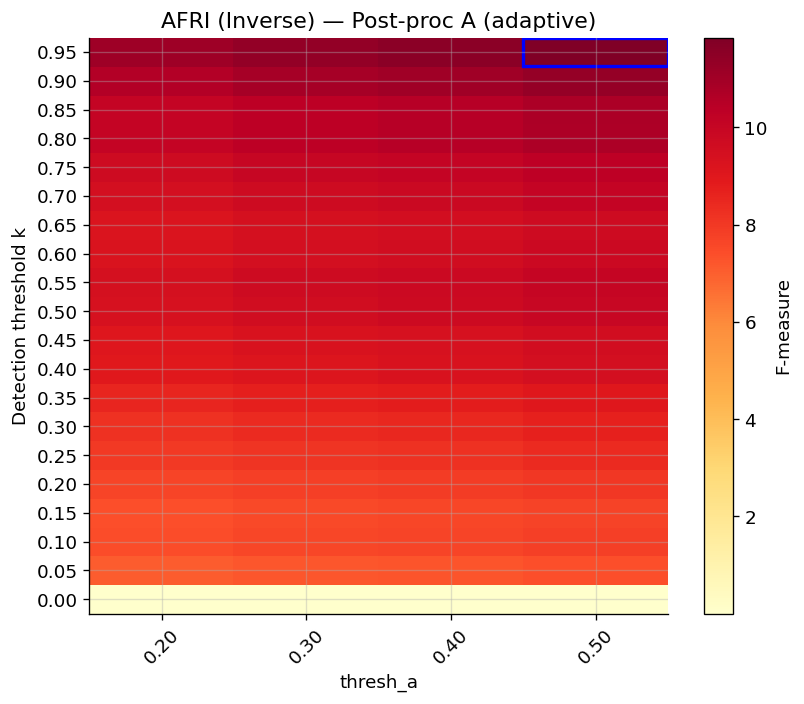

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.venv/lib/python3.7/site-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  import sys


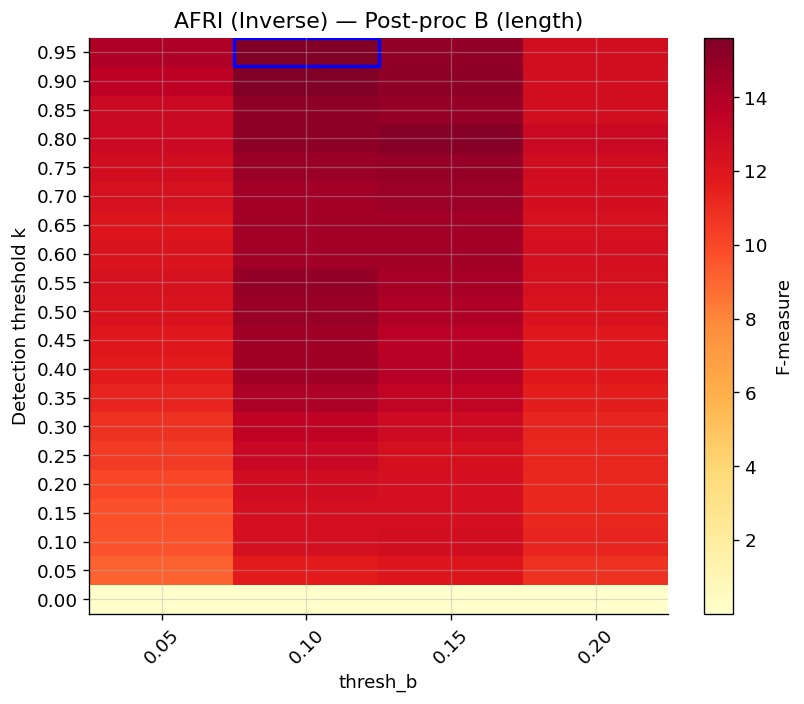

In [7]:
def plot_heatmap(df, k_col, pp_col, label, title_suffix, fname_suffix):
    pivot = df.pivot_table(index=k_col, columns=pp_col, values="fmeasure", aggfunc="max")
    if pivot.empty:
        return
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd", origin="lower")
    plt.colorbar(im, ax=ax, label="F-measure")

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f"{v:.2f}" for v in pivot.columns], rotation=45)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([f"{v:.2f}" for v in pivot.index])

    # Mark best cell
    best_flat = pivot.values.argmax()
    best_row, best_col = divmod(best_flat, pivot.values.shape[1])
    ax.add_patch(plt.Rectangle((best_col - 0.5, best_row - 0.5), 1, 1,
                                fill=False, edgecolor="blue", linewidth=2))

    ax.set_xlabel(pp_col)
    ax.set_ylabel("Detection threshold k")
    ax.set_title(f"{label} — {title_suffix}")
    plt.tight_layout()
    safe_label = label.replace(" ", "_").replace("/", "-").replace("(", "").replace(")", "")
    plt.savefig(f"fig_heatmap_{safe_label}_{fname_suffix}.pdf", bbox_inches="tight")
    plt.show()


for label in exp_labels:
    sub_A = df_sweepA[df_sweepA["experiment"] == label]
    sub_B = df_sweepB[df_sweepB["experiment"] == label]
    if not sub_A.empty:
        plot_heatmap(sub_A, "k", "thresh_a", label, "Post-proc A (adaptive)", "ppA")
    if not sub_B.empty:
        plot_heatmap(sub_B, "k", "thresh_b", label, "Post-proc B (length)", "ppB")

## 6 — Winning Threshold Comparison Across Experiments

In [8]:
rows = []
for label, data in experiments.items():
    if data is None:
        continue
    final_fm = data["final"].get("fmeasure")
    winning_k = None
    winning_thresh = None
    proc_type = None
    for entry in data["best_A"]:
        if entry.get("fmeasure") == final_fm:
            winning_k = entry["k"]
            winning_thresh = entry["winning_thresh"]
            proc_type = "A (adaptive)"
            break
    if proc_type is None:
        for entry in data["best_B"]:
            if entry.get("fmeasure") == final_fm:
                winning_k = entry["k"]
                winning_thresh = entry["winning_thresh"]
                proc_type = "B (length)"
                break
    rows.append({
        "Experiment": label,
        "Best F-measure": final_fm,
        "Winning detection k": winning_k,
        "Winning post-proc thresh": winning_thresh,
        "Post-proc type": proc_type,
    })

df_winning = pd.DataFrame(rows).set_index("Experiment")
print("=== Winning Threshold Configuration per Experiment ===")
display(df_winning)

=== Winning Threshold Configuration per Experiment ===


,Best F-measure,Winning detection k,Winning post-proc thresh,Post-proc type
Experiment,,,,
Baseline,16.615,0.85,0.15,B (length)
CIFE,15.296,0.50,0.15,B (length)
Slot Uniform,15.392,0.95,0.10,B (length)
Phase 1 (Random),15.618,0.95,0.10,B (length)
Phase 2 (Energy),15.434,0.90,0.10,B (length)
Phase 3 (Activation),15.304,0.95,0.15,B (length)
AFRI (Direct),15.502,0.75,0.15,B (length)
AFRI (Inverse),15.613,0.95,0.10,B (length)


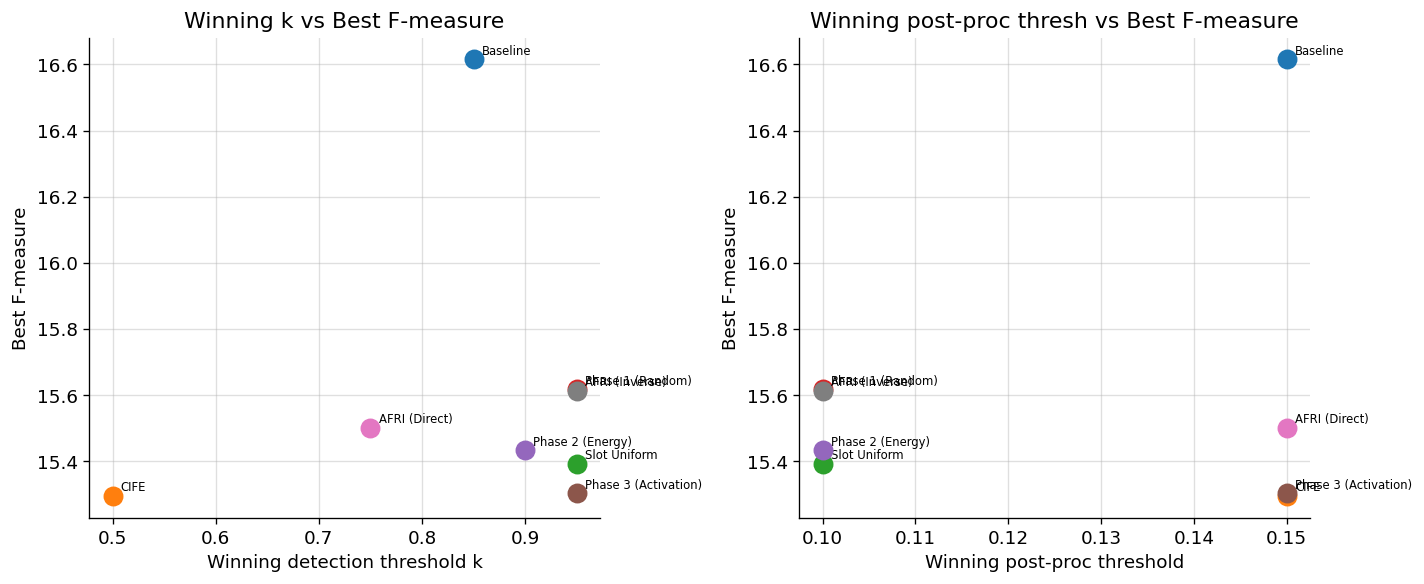

In [9]:
# Scatter: winning detection k vs F-measure
if not df_winning.empty and "Winning detection k" in df_winning.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for i_e, (label, row) in enumerate(df_winning.iterrows()):
        axes[0].scatter(row["Winning detection k"], row["Best F-measure"],
                        s=120, color=COLORS[i_e % len(COLORS)], zorder=3)
        axes[0].annotate(label, (row["Winning detection k"], row["Best F-measure"]),
                         textcoords="offset points", xytext=(5, 3), fontsize=7)

    axes[0].set_xlabel("Winning detection threshold k")
    axes[0].set_ylabel("Best F-measure")
    axes[0].set_title("Winning k vs Best F-measure")

    for i_e, (label, row) in enumerate(df_winning.iterrows()):
        axes[1].scatter(row["Winning post-proc thresh"], row["Best F-measure"],
                        s=120, color=COLORS[i_e % len(COLORS)], zorder=3)
        axes[1].annotate(label, (row["Winning post-proc thresh"], row["Best F-measure"]),
                         textcoords="offset points", xytext=(5, 3), fontsize=7)

    axes[1].set_xlabel("Winning post-proc threshold")
    axes[1].set_ylabel("Best F-measure")
    axes[1].set_title("Winning post-proc thresh vs Best F-measure")

    plt.tight_layout()
    plt.savefig("fig_winning_thresholds.pdf", bbox_inches="tight")
    plt.show()